# **Analyse des facteurs associés au niveau de revenu — Adult Census Income**

## **Introduction et présentation du projet**

Ce projet porte sur l'analyse du jeu de données **Adult Census Income**, qui contient des informations démographiques, professionnelles et socio-économiques relatives à des individus.

L'objectif principal est d'étudier les caractéristiques associées au niveau de revenu et de développer des modèles de Machine Learning permettant de prédire si le revenu annuel d'un individu est supérieur à 50 000 dollars.

La variable cible `income` comporte deux catégories : `<=50K` et `>50K`.

Le travail comprend plusieurs étapes : exploration et nettoyage des données, analyse statistique descriptive, étude des relations entre les variables explicatives et le revenu, puis construction, comparaison et optimisation de modèles de classification.

Ce projet permet ainsi de mettre en pratique les méthodes d'analyse statistique et les techniques de Machine Learning dans le cadre d'une problématique de classification binaire.

# **1. Installation et importation des bibliothèques**

Cette section présente les bibliothèques utilisées
pour le chargement, la manipulation, l'analyse
et la visualisation des données.

In [ ]:

# Importation des bibliothèques

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Style des visualisations
sns.set_theme(style="whitegrid")



# **2. Chargement du dataset**

Nous utilisons le dataset Adult Census Income,
disponible sur Kaggle.

L'objectif est de charger les données dans un
DataFrame pandas afin de réaliser les analyses
statistiques nécessaires.


In [ ]:

# Téléchargement du dataset depuis Kaggle

import kagglehub

dataset_path = kagglehub.dataset_download(
    "uciml/adult-census-income"
)

# Localisation du fichier CSV
csv_path = os.path.join(dataset_path, "adult.csv")

# Lecture du fichier
df = pd.read_csv(csv_path, skipinitialspace=True)

# Nettoyage des noms de colonnes
df.columns = df.columns.str.strip()

# Affichage des premières lignes
df.head()


Using Colab cache for faster access to the 'adult-census-income' dataset.


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K



# **3. Exploration initiale des données**


In [ ]:

# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
df.info()


Dimensions : (32561, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
# Statistiques descriptives
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education.num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital.status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **4. Data Cleaning**




**4.1 Diagnostic des valeurs manquantes et des doublons**

In [ ]:

# Création d'une copie pour le diagnostic
df_check = df.copy()

# Suppression des espaces inutiles
for col in df_check.select_dtypes(include="object").columns:
    df_check[col] = df_check[col].str.strip()

# Remplacer '?' par NaN dans la copie
df_check = df_check.replace("?", np.nan)

# Nombre de doublons
print("Nombre de doublons :", df_check.duplicated().sum())

# Nombre de valeurs manquantes par variable
missing_values = df_check.isnull().sum()

# Pourcentage de valeurs manquantes
missing_percentage = (
    df_check.isnull().mean() * 100
).round(2)

# Tableau récapitulatif
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

print("\nDiagnostic des valeurs manquantes :")
display(missing_summary)


Nombre de doublons : 24

Diagnostic des valeurs manquantes :


,Missing Values,Percentage (%)
age,0,0.00
workclass,1836,5.64
fnlwgt,0,0.00
education,0,0.00
education.num,0,0.00
marital.status,0,0.00
occupation,1843,5.66
relationship,0,0.00
race,0,0.00
sex,0,0.00


 **4.2 Suppression des doublons**

In [ ]:

# Suppression des lignes dupliquées

initial_shape = df_check.shape

df = df_check.drop_duplicates().copy()

final_shape = df.shape

print("Dimensions initiales :", initial_shape)
print("Dimensions après suppression :", final_shape)

print("Nombre de doublons restants :",
      df.duplicated().sum())


Dimensions initiales : (32561, 15)
Dimensions après suppression : (32537, 15)
Nombre de doublons restants : 0


 **4.3 Analyse des valeurs manquantes après suppression des doublons**

In [ ]:

# Analyse des valeurs manquantes après nettoyage

missing_summary = pd.DataFrame({
    "Nombre de valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": (df.isnull().mean() * 100).round(2)
})

display(missing_summary[missing_summary["Nombre de valeurs manquantes"] > 0])


,Nombre de valeurs manquantes,Pourcentage (%)
workclass,1836,5.64
occupation,1843,5.66
native.country,582,1.79


 **4.4 Traitement des valeurs manquantes**

Les valeurs manquantes des variables catégorielles
sont remplacées par une catégorie "Unknown".

Cette approche permet de conserver les observations
et d'identifier explicitement les informations non renseignées.

In [ ]:

# Identification des variables concernées

cat_missing_cols = [
    "workclass",
    "occupation",
    "native.country"
]

# Remplacement des valeurs manquantes
df[cat_missing_cols] = df[cat_missing_cols].fillna("Unknown")

# Vérification après imputation
print("Valeurs manquantes restantes :")
print(df.isnull().sum().sum())

# Nombre de valeurs remplacées
print("\nNombre de valeurs Unknown :")
print(df[cat_missing_cols].eq("Unknown").sum())


Valeurs manquantes restantes :
0

Nombre de valeurs Unknown :
workclass         1836
occupation        1843
native.country     582
dtype: int64


**4.5 Vérification des types de données**

In [ ]:

# Types de données de chaque variable

print("Types des variables :")
display(df.dtypes)

# Nombre de variables par type
print("\nRépartition des types :")
print(df.dtypes.value_counts())


Types des variables :


,0
age,int64
workclass,object
fnlwgt,int64
education,object
education.num,int64
marital.status,object
occupation,object
relationship,object
race,object
sex,object



Répartition des types :
object    9
int64     6
Name: count, dtype: int64


# **5. **Analyse** descriptive des variables quantitatives**

Cette étape consiste à examiner les principales caractéristiques statistiques des variables quantitatives, notamment la moyenne, l'écart-type, le minimum, le maximum et les quartiles.

In [ ]:

# Sélection des variables quantitatives
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Statistiques descriptives
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
age,32537.0,38.585549,13.637984,17.0,28.0,37.0,48.0,90.0
fnlwgt,32537.0,189780.848511,105556.471009,12285.0,117827.0,178356.0,236993.0,1484705.0
education.num,32537.0,10.081815,2.571633,1.0,9.0,10.0,12.0,16.0
capital.gain,32537.0,1078.443741,7387.957424,0.0,0.0,0.0,0.0,99999.0
capital.loss,32537.0,87.368227,403.101833,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32537.0,40.440329,12.346889,1.0,40.0,40.0,45.0,99.0


**Interprétation :**

Les statistiques descriptives montrent que l'âge moyen des individus est de 38,59 ans, tandis que le nombre moyen d'heures travaillées par semaine est de 40,44 heures. Le niveau moyen d'éducation est de 10,08.

Les variables `capital.gain` et `capital.loss` présentent une forte concentration de valeurs nulles, ce qui indique que la majorité des individus ne déclarent aucun gain ou perte en capital.

Enfin, la variable `fnlwgt` représente un poids d'échantillonnage statistique et nécessite une interprétation particulière.

# **Détection des valeurs aberrantes**

L'objectif de cette étape est d'identifier les observations qui présentent des valeurs extrêmes dans les variables quantitatives, à l'aide de la méthode de l'écart interquartile (IQR).

In [ ]:

# Détection des valeurs aberrantes par la méthode IQR

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    nb_outliers = ((df[col] < borne_inf) |
                   (df[col] > borne_sup)).sum()

    print(f"{col} : {nb_outliers} valeurs aberrantes")


age : 142 valeurs aberrantes
fnlwgt : 993 valeurs aberrantes
education.num : 1193 valeurs aberrantes
capital.gain : 2712 valeurs aberrantes
capital.loss : 1519 valeurs aberrantes
hours.per.week : 9002 valeurs aberrantes


# **Visualisation des valeurs aberrantes**

Afin de mieux comprendre la distribution des variables quantitatives et de visualiser les valeurs extrêmes détectées, nous utilisons des diagrammes en boîte (Boxplots).

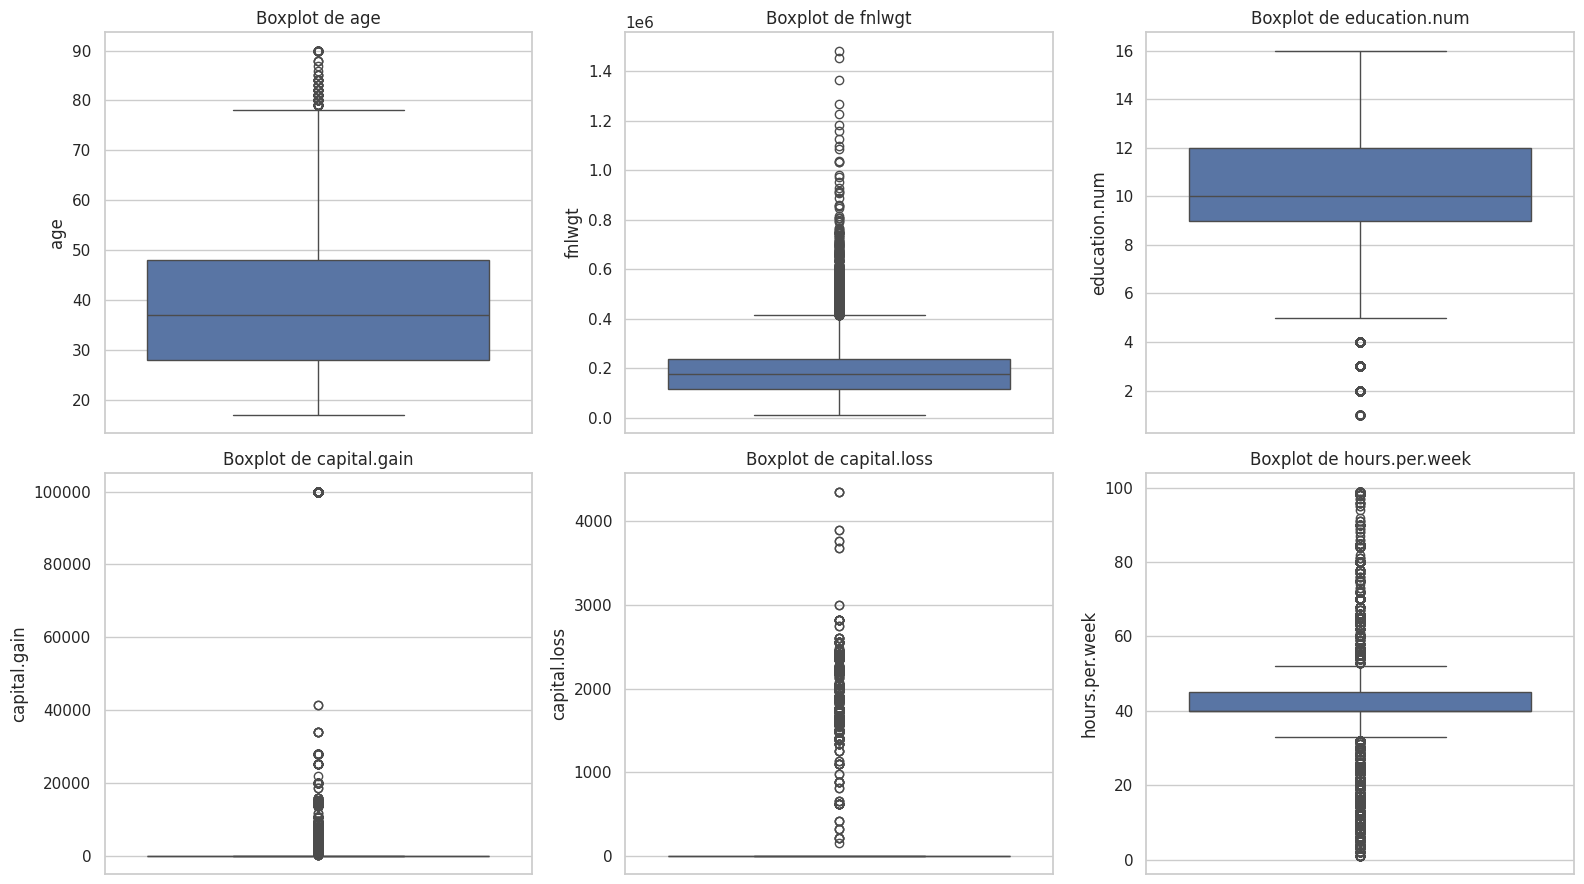

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

#**6. Analyse descriptive des variables qualitatives**

**6.1.
Analyse de la distribution de la variable cible (Income)**

Après les étapes de nettoyage et de préparation des données, nous passons à l'analyse exploratoire des données (EDA).

Dans cette première étape, nous étudions la distribution de la variable cible **income**, qui représente la catégorie de revenu annuel des individus.

L'objectif est de :
- Examiner la répartition des individus selon leur niveau de revenu.
- Calculer les effectifs et les pourcentages de chaque catégorie.
- Identifier un éventuel déséquilibre entre les deux classes de revenus.

Cette analyse permettra de mieux comprendre la structure de notre variable cible avant de passer à l'étude des relations entre les différentes variables explicatives et le revenu.

Répartition des revenus :
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Pourcentage des revenus :
income
<=50K    75.91
>50K     24.09
Name: proportion, dtype: float64


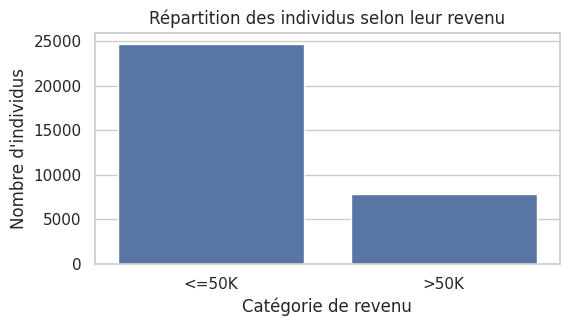

In [ ]:

# Distribution de la variable cible : income

print("Répartition des revenus :")
print(df['income'].value_counts())

print("\nPourcentage des revenus :")
print((df['income'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 3))

sns.countplot(data=df, x='income')

plt.title("Répartition des individus selon leur revenu")
plt.xlabel("Catégorie de revenu")
plt.ylabel("Nombre d'individus")

plt.show()


**Interprétation des résultats**

L'analyse de la variable cible `income` montre que 75,91 % des individus appartiennent à la catégorie de revenu inférieur ou égal à 50K, contre 24,09 % pour la catégorie supérieure à 50K.

Cette répartition met en évidence un déséquilibre entre les deux classes. La catégorie `<=50K` est largement majoritaire par rapport à la catégorie `>50K`.

Ce déséquilibre devra être pris en considération lors de la phase de modélisation, afin d'éviter que les modèles de Machine Learning privilégient systématiquement la classe majoritaire.



**6.2.Étude de la variable Workclass**

Dans cette étape, nous commençons l'analyse univariée des variables catégorielles par l'étude de la variable `workclass`, qui représente le type de secteur professionnel auquel appartient chaque individu.

L'objectif de cette analyse est de :
- Identifier les différentes catégories professionnelles présentes dans le dataset.
- Calculer les effectifs et les fréquences de chaque catégorie.
- Visualiser la répartition des individus selon leur statut professionnel.
- Repérer les catégories les plus représentées.

,Effectif,Pourcentage (%)
workclass,,
Private,22673,69.68%
Self-emp-not-inc,2540,7.81%
Local-gov,2093,6.43%
Unknown,1836,5.64%
State-gov,1298,3.99%
Self-emp-inc,1116,3.43%
Federal-gov,960,2.95%
Without-pay,14,0.04%
Never-worked,7,0.02%


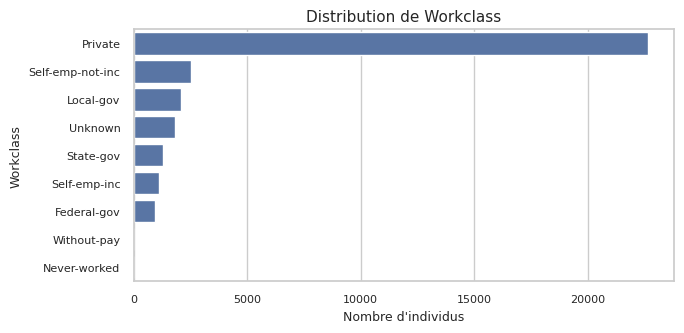

In [ ]:

# Analyse de la variable workclass

workclass_counts = df['workclass'].value_counts()
workclass_percentages = (
    df['workclass'].value_counts(normalize=True) * 100
).round(2)

workclass_summary = pd.DataFrame({
    'Effectif': workclass_counts,
    'Pourcentage (%)': workclass_percentages
})

# Affichage compact du tableau
display(workclass_summary.style
        .format({'Pourcentage (%)': '{:.2f}%'} )
        .set_table_styles([
            {'selector': 'th, td',
             'props': [('font-size', '10px'),
                       ('padding', '3px 8px')]}
        ]))

# Graphique compact
plt.figure(figsize=(7, 3.5))

sns.countplot(
    data=df,
    y='workclass',
    order=workclass_counts.index
)

plt.title("Distribution de Workclass", fontsize=11)
plt.xlabel("Nombre d'individus", fontsize=9)
plt.ylabel("Workclass", fontsize=9)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()


## **7.Relation entre les variables qualitatives et le revenu.**

**Relation entre Workclass et Income**

---



Cette analyse permet d'étudier la répartition des niveaux de revenu selon les différentes catégories de statut professionnel.


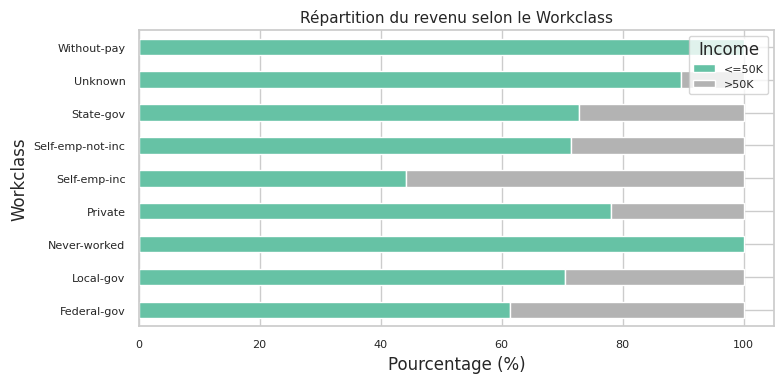

In [ ]:

workclass_income = pd.crosstab(
    df['workclass'],
    df['income'],
    normalize='index'
) * 100

workclass_income.plot(
    kind='barh',
    stacked=True,
    figsize=(8, 4),
    colormap='Set2'
)

plt.title("Répartition du revenu selon le Workclass", fontsize=11)
plt.xlabel("Pourcentage (%)")
plt.ylabel("Workclass")
plt.legend(title="Income", fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()



**Interprétation :**

La répartition du revenu varie selon la catégorie professionnelle. Les catégories `Self-emp-inc` et `Federal-gov` présentent des proportions relativement plus élevées de personnes ayant un revenu supérieur à 50K, tandis que la catégorie `Private` est majoritairement représentée par des revenus inférieurs ou égaux à 50K.

Ces résultats montrent une association entre le statut professionnel et le niveau de revenu, sans permettre de conclure à une relation de causalité. Les catégories ayant de faibles effectifs doivent être interprétées avec prudence.


**Relation entre Education et Income**

Cette analyse vise à étudier la répartition des niveaux de revenu selon le niveau d'éducation, afin d'identifier les éventuelles associations entre ces deux variables.


income,<=50K,>50K
education,,
Preschool,100.00%,0.00%
1st-4th,96.39%,3.61%
5th-6th,95.18%,4.82%
11th,94.89%,5.11%
9th,94.75%,5.25%
7th-8th,93.80%,6.20%
10th,93.35%,6.65%
12th,92.38%,7.62%
HS-grad,84.05%,15.95%


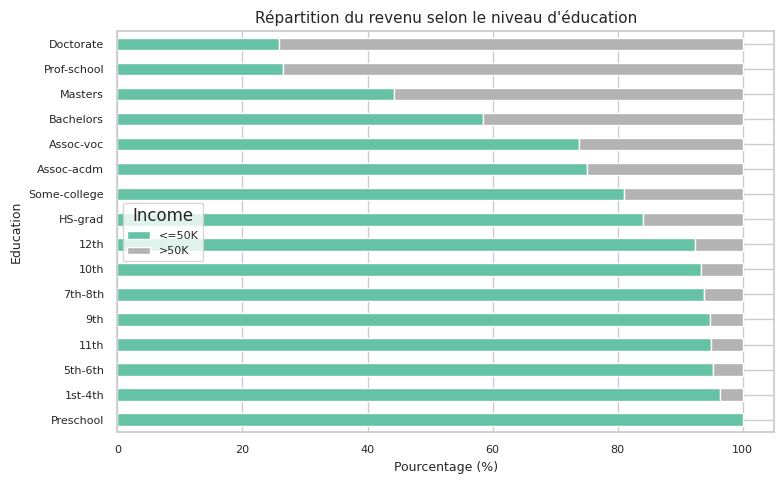

In [ ]:

# Calcul des pourcentages de revenu pour chaque niveau d'éducation
education_income = pd.crosstab(
    df['education'],
    df['income'],
    normalize='index'
) * 100

# Organiser les catégories selon la proportion de revenus >50K
education_income = education_income.reindex(
    columns=['<=50K', '>50K']
).sort_values(by='>50K')

# Afficher le tableau
display(
    education_income.round(2).style
    .format('{:.2f}%')
    .set_table_styles([
        {'selector': 'th, td',
         'props': [('font-size', '10px'), ('padding', '3px 8px')]}
    ])
)

# Représentation graphique
education_income.plot(
    kind='barh',
    stacked=True,
    figsize=(8, 5),
    colormap='Set2'
)

plt.title("Répartition du revenu selon le niveau d'éducation", fontsize=11)
plt.xlabel("Pourcentage (%)", fontsize=9)
plt.ylabel("Education", fontsize=9)
plt.legend(title="Income", fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()



**Interprétation :**

Les résultats montrent une association positive entre le niveau d'éducation et le revenu. En général, la proportion des individus ayant un revenu supérieur à 50K augmente avec le niveau d'études. Cette proportion atteint 74,09 % pour les titulaires d'un Doctorate et 73,44 % pour les personnes ayant un niveau Prof-school, contre seulement 15,95 % pour les individus ayant un niveau HS-grad.

Ces observations suggèrent que le niveau d'éducation est associé au niveau de revenu. Toutefois, cette relation ne signifie pas nécessairement un lien de causalité.


 **Relation entre Marital Status et Income**

Cette analyse vise à étudier la répartition des niveaux de revenu selon la situation matrimoniale des individus.


income,<=50K,>50K
marital.status,,
Never-married,95.40,4.60
Separated,93.56,6.44
Married-spouse-absent,91.87,8.13
Widowed,91.44,8.56
Divorced,89.57,10.43
Married-AF-spouse,56.52,43.48
Married-civ-spouse,55.31,44.69


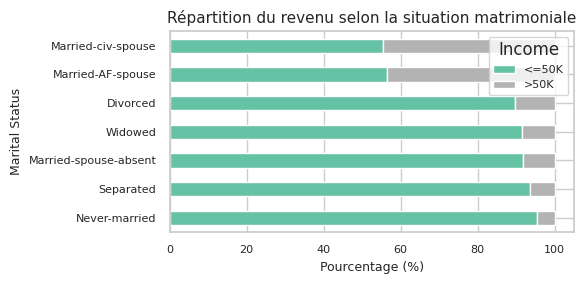

In [ ]:

# Calcul des pourcentages selon la situation matrimoniale
marital_income = pd.crosstab(
    df['marital.status'],
    df['income'],
    normalize='index'
) * 100

# Trier selon la proportion de revenus >50K
marital_income = marital_income.reindex(
    columns=['<=50K', '>50K']
).sort_values(by='>50K')

# Afficher le tableau
display(marital_income.round(2))

# Visualisation
marital_income.plot(
    kind='barh',
    stacked=True,
    figsize=(6, 3),
    colormap='Set2'
)

plt.title("Répartition du revenu selon la situation matrimoniale", fontsize=11)
plt.xlabel("Pourcentage (%)", fontsize=9)
plt.ylabel("Marital Status", fontsize=9)
plt.legend(title="Income", fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()



### **8. Relation entre les variables quantitatives et le revenu**

Cette analyse permet de comparer la distribution des variables quantitatives selon les deux catégories de revenu (`<=50K` et `>50K`).


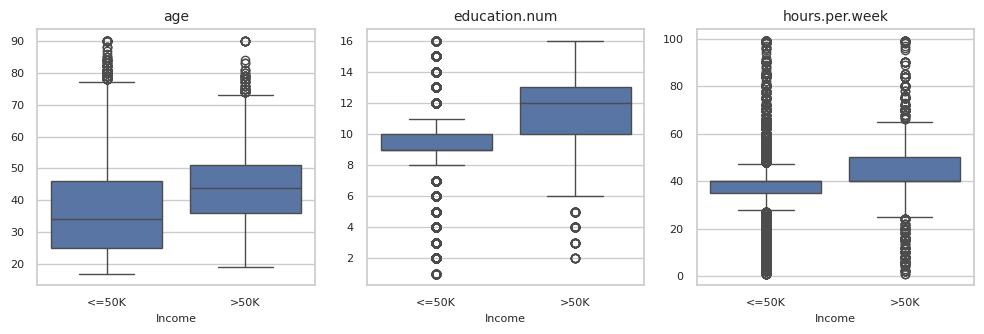

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

variables = ['age', 'education.num', 'hours.per.week']

for ax, col in zip(axes, variables):
    sns.boxplot(data=df, x='income', y=col, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Income", fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()



**Interprétation :**

Les boxplots mettent en évidence des différences entre les deux catégories de revenu.

Les individus ayant un revenu supérieur à 50K présentent généralement un âge médian plus élevé et un niveau d'éducation médian supérieur à ceux ayant un revenu inférieur ou égal à 50K.

Concernant le nombre d'heures travaillées par semaine, les deux groupes présentent une médiane proche de 40 heures, mais la distribution diffère, avec un troisième quartile plus élevé pour le groupe `>50K`.

Ces observations suggèrent que l'âge, le niveau d'éducation et le temps de travail sont associés au niveau de revenu.


**Analyse de Capital Gain et Capital Loss selon le revenu**

Cette analyse permet d'examiner la fréquence des gains et des pertes en capital selon les catégories de revenu.


In [ ]:

capital_summary = df.groupby('income').agg(
    Capital_Gain_Positive=('capital.gain', lambda x: (x > 0).mean() * 100),
    Capital_Loss_Positive=('capital.loss', lambda x: (x > 0).mean() * 100)
).round(2)

display(capital_summary)


,Capital_Gain_Positive,Capital_Loss_Positive
income,,
<=50K,4.19,3.02
>50K,21.39,9.86



**Interprétation :**

Les résultats montrent que 21,39 % des individus ayant un revenu supérieur à 50K présentent un capital gain positif, contre seulement 4,19 % dans la catégorie <=50K.

De même, la proportion des individus ayant un capital loss positif est plus élevée dans la catégorie >50K (9,86 %) que dans la catégorie <=50K (3,02 %).

Ces observations suggèrent une association entre les variables liées au capital et le niveau de revenu.



## **9. Préparation et modélisation des données pour le Machine Learning**

Avant de construire les modèles prédictifs, la variable cible `income` doit être transformée en valeurs numériques.


In [ ]:

# Création d'une copie pour le Machine Learning
df_ml = df.copy()

# Encodage de la variable cible
df_ml['income'] = df_ml['income'].map({
    '<=50K': 0,
    '>50K': 1
})

# Vérification
print("Valeurs de la variable cible :")
print(df_ml['income'].value_counts())

print("\nValeurs manquantes dans la cible :")
print(df_ml['income'].isna().sum())


Valeurs de la variable cible :
income
0    24698
1     7839
Name: count, dtype: int64

Valeurs manquantes dans la cible :
0



### **9.1. Division des données en ensembles d'entraînement et de test**

Les données sont divisées en deux ensembles : un ensemble d'entraînement pour construire les modèles et un ensemble de test pour évaluer leurs performances sur des données non utilisées pendant l'apprentissage.

La stratification permet de conserver approximativement la même proportion des deux classes de revenu dans les deux ensembles.


In [ ]:

from sklearn.model_selection import train_test_split

# Séparation des variables explicatives et de la variable cible
X = df_ml.drop('income', axis=1)
y = df_ml['income']

# Division des données : 80% entraînement et 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Vérification
print("Taille de X_train :", X_train.shape)
print("Taille de X_test :", X_test.shape)

print("\nRépartition des classes dans y_train :")
print(y_train.value_counts(normalize=True).round(3))

print("\nRépartition des classes dans y_test :")
print(y_test.value_counts(normalize=True).round(3))


Taille de X_train : (26029, 14)
Taille de X_test : (6508, 14)

Répartition des classes dans y_train :
income
0    0.759
1    0.241
Name: proportion, dtype: float64

Répartition des classes dans y_test :
income
0    0.759
1    0.241
Name: proportion, dtype: float64



9.2. Prétraitement des données et modélisation par régression **logis

Le prétraitement consiste à standardiser les variables quantitatives et à encoder les variables qualitatives.

Un modèle de régression logistique est ensuite entraîné pour prédire la catégorie de revenu. L'option `class_weight='balanced'` est utilisée afin de tenir compte du déséquilibre entre les deux classes.


**9.2. Prétraitement des données et modélisation par régression logistique.**

Variables quantitatives : 6
Variables qualitatives : 8
Accuracy : 0.8096
Precision : 0.5722
Recall : 0.831
F1-score : 0.6778
ROC-AUC : 0.9024

Rapport de classification :
              precision    recall  f1-score   support

           0       0.94      0.80      0.86      4940
           1       0.57      0.83      0.68      1568

    accuracy                           0.81      6508
   macro avg       0.75      0.82      0.77      6508
weighted avg       0.85      0.81      0.82      6508



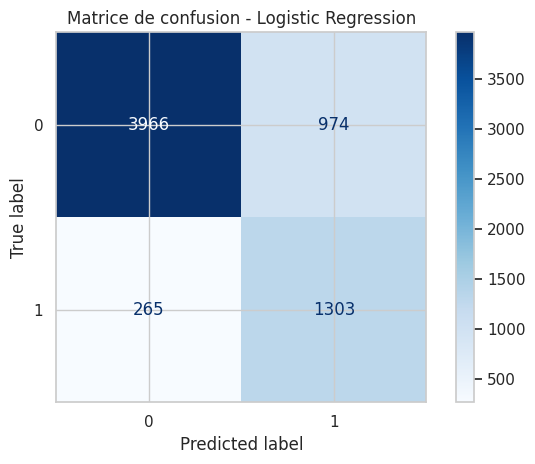

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    roc_auc_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Identification des variables quantitatives et qualitatives
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include='object').columns.tolist()

print("Variables quantitatives :", len(numeric_features))
print("Variables qualitatives :", len(categorical_features))

# Prétraitement
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Construction du pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Entraînement
logistic_model.fit(X_train, y_train)

# Prédictions
y_pred = logistic_model.predict(X_test)
y_proba = logistic_model.predict_proba(X_test)[:, 1]

# Évaluation
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, y_proba), 4))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap='Blues',
    values_format='d'
)
plt.title("Matrice de confusion - Logistic Regression")
plt.tight_layout()
plt.show()


**9.3. Comparaison de plusieurs modèles de classification**

Afin d'évaluer les performances de différentes approches, nous comparons trois algorithmes : Logistic Regression, Decision Tree et Random Forest, en utilisant les mêmes ensembles d'entraînement et de test.


In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Définition des modèles
models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        class_weight='balanced',
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_split=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Évaluation des deux modèles
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-score': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })

# Ajouter les résultats de Logistic Regression
results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
})

comparison = pd.DataFrame(results).set_index('Model')

display(comparison.round(4))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree,0.7964,0.5513,0.8323,0.6633,0.8664
Random Forest,0.8039,0.5618,0.8469,0.6755,0.9068
Logistic Regression,0.8096,0.5722,0.8310,0.6778,0.9024



### **Interprétation de la comparaison des modèles**

La comparaison montre que les trois modèles présentent des performances différentes.

Le modèle Logistic Regression obtient les meilleures valeurs d'Accuracy (80,96 %), de Precision (57,22 %) et de F1-score (67,78 %).

Le modèle Random Forest présente le meilleur Recall (84,69 %) et le meilleur ROC-AUC (90,68 %), ce qui indique une bonne capacité à identifier les individus appartenant aux deux catégories de revenu.

Le modèle Decision Tree présente des performances globalement inférieures aux deux autres modèles.

Ainsi, Random Forest est retenu comme modèle privilégié pour la suite de l'analyse, tout en conservant Logistic Regression comme modèle de référence.



### **9.4.Importance des variables**

Cette étape permet d'identifier les variables qui contribuent le plus aux prédictions du modèle Random Forest.


,Importance
Variable,
marital.status_Married-civ-spouse,0.1522
capital.gain,0.0962
marital.status_Never-married,0.0849
education.num,0.0827
relationship_Husband,0.0769
age,0.0742
hours.per.week,0.0480
relationship_Own-child,0.0354
relationship_Not-in-family,0.0250


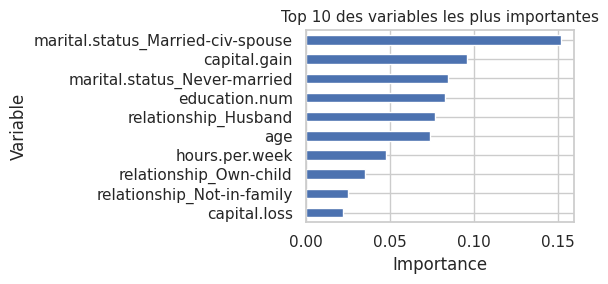

In [ ]:

# Construction du modèle Random Forest retenu
rf_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_split=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Entraînement
rf_pipeline.fit(X_train, y_train)

# Extraction de l'importance des variables
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = rf_pipeline.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Importance': importances
})

# Regrouper les variables originales
importance_df['Variable'] = importance_df['Variable'].str.replace(
    r'^(num__|cat__)', '', regex=True
)

importance_df = importance_df.groupby('Variable')['Importance'].sum()
importance_df = importance_df.sort_values(ascending=False).head(10)

display(importance_df.round(4))

# Visualisation
importance_df.sort_values().plot(
    kind='barh',
    figsize=(6, 3)
)

plt.title("Top 10 des variables les plus importantes", fontsize=11)
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()



### **Interprétation de l'importance des variables**

L'analyse de l'importance des variables montre que la catégorie `Married-civ-spouse` est la caractéristique la plus importante dans les prédictions du modèle Random Forest, avec une importance de 0,1522.

Elle est suivie par `capital.gain` (0,0962), `Never-married` (0,0849) et `education.num` (0,0827). L'âge et le nombre d'heures travaillées par semaine contribuent également aux prédictions.

Ces résultats mettent en évidence l'importance des caractéristiques liées à la situation matrimoniale, au capital et à l'éducation dans la prédiction du revenu. Toutefois, l'importance des variables ne représente pas une relation de causalité.


 **9.5. Optimisation des hyperparamètres du modèle Random Forest**

Cette étape consiste à rechercher une meilleure combinaison d'hyperparamètres afin d'améliorer les performances du modèle Random Forest, en utilisant une validation croisée.


In [ ]:

from sklearn.model_selection import RandomizedSearchCV

rf_pipeline_tuning = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__max_depth': [10, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline_tuning,
    param_distributions=param_distributions,
    n_iter=6,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(random_search.best_params_)

print("\nMeilleur F1-score (validation croisée) :")
print(round(random_search.best_score_, 4))


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Meilleurs paramètres :
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 20}

Meilleur F1-score (validation croisée) :
0.7032


,Importance
Variable,
marital.status_Married-civ-spouse,0.1382
capital.gain,0.0911
age,0.0899
education.num,0.0785
marital.status_Never-married,0.0748
relationship_Husband,0.0604
hours.per.week,0.0560
fnlwgt,0.0341
relationship_Own-child,0.0307


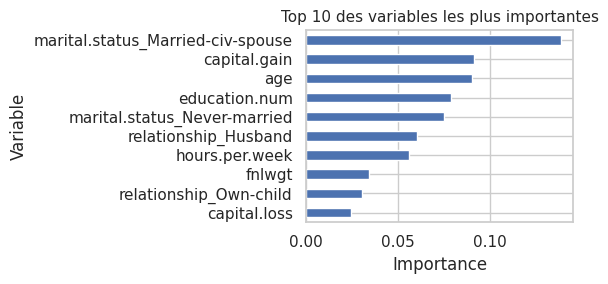

In [ ]:

# Utilisation du meilleur modèle optimisé
best_model = random_search.best_estimator_

# Extraction des noms et des importances
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
importances = best_model.named_steps['classifier'].feature_importances_

# Création du tableau
importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Importance': importances
})

# Regroupement des variables originales
importance_df['Variable'] = importance_df['Variable'].str.replace(
    r'^(num__|cat__)', '', regex=True
)

importance_df = (
    importance_df.groupby('Variable')['Importance']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(importance_df.round(4))

# Visualisation
plt.figure(figsize=(6, 3))
importance_df.sort_values().plot(kind='barh')
plt.title("Top 10 des variables les plus importantes", fontsize=11)
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()



### **9.6.Évaluation du modèle Random Forest optimisé**

Le meilleur modèle obtenu après l'optimisation des hyperparamètres est évalué sur l'ensemble de test afin de comparer ses performances avec celles du modèle initial.


In [ ]:

# Récupération du meilleur modèle
best_rf = random_search.best_estimator_

# Prédictions sur les données de test
y_pred_tuned = best_rf.predict(X_test)
y_proba_tuned = best_rf.predict_proba(X_test)[:, 1]

# Évaluation du modèle optimisé
print("Résultats du Random Forest optimisé :")
print("Accuracy :", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision :", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall :", round(recall_score(y_test, y_pred_tuned), 4))
print("F1-score :", round(f1_score(y_test, y_pred_tuned), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, y_proba_tuned), 4))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_tuned))


Résultats du Random Forest optimisé :
Accuracy : 0.8248
Precision : 0.5999
Recall : 0.8195
F1-score : 0.6927
ROC-AUC : 0.9083

Rapport de classification :
              precision    recall  f1-score   support

           0       0.94      0.83      0.88      4940
           1       0.60      0.82      0.69      1568

    accuracy                           0.82      6508
   macro avg       0.77      0.82      0.79      6508
weighted avg       0.85      0.82      0.83      6508



 **9.7. Comparaison avant et après optimisation**

Après l'optimisation des hyperparamètres, le modèle Random Forest présente une amélioration de ses performances.

L'Accuracy passe de 80,39 % à 82,48 %, tandis que le F1-score augmente de 0,6755 à 0,6927. Le ROC-AUC progresse également légèrement, passant de 0,9068 à 0,9083.

Cependant, le Recall diminue de 0,8469 à 0,8195.

Malgré cette diminution, le modèle optimisé est retenu pour la suite, car il offre un meilleur équilibre global entre les principales métriques d'évaluation.


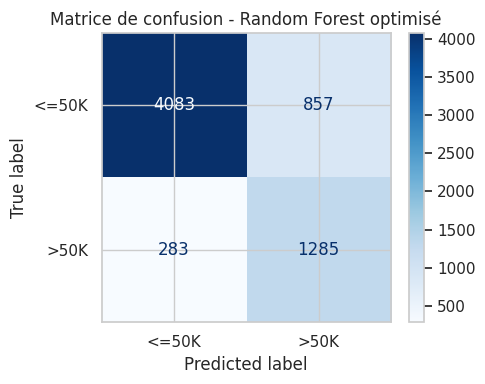

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=['<=50K', '>50K'],
    cmap='Blues',
    ax=ax
)

ax.set_title("Matrice de confusion - Random Forest optimisé")
plt.tight_layout()
plt.show()



### **Interprétation de la matrice de confusion**

La matrice de confusion du modèle Random Forest optimisé montre que le modèle a correctement classé 4083 individus appartenant à la catégorie de revenu inférieur ou égal à 50K et 1285 individus appartenant à la catégorie de revenu supérieur à 50K.

Cependant, 857 individus de la première catégorie ont été classés à tort dans la catégorie supérieure à 50K, tandis que 283 individus de la catégorie supérieure ont été classés à tort dans la catégorie inférieure ou égale à 50K.

Ces résultats montrent que le modèle identifie correctement une grande partie des individus des deux catégories de revenu, avec une meilleure reconnaissance de la classe majoritaire.


**9.8.Comparaison finale des modèles de classification**

Après avoir comparé trois modèles de classification, nous avons procédé à l'optimisation des hyperparamètres du modèle Random Forest à l'aide de RandomizedSearchCV et d'une validation croisée.

Cette étape permet de comparer les performances du modèle optimisé avec celles des modèles initiaux afin d'évaluer l'apport de cette optimisation.

In [ ]:

comparison_final = pd.DataFrame({
    'Modèle': [
        'Decision Tree',
        'Random Forest',
        'Logistic Regression',
        'Random Forest optimisé'
    ],
    'Accuracy': [0.7964, 0.8039, 0.8096, 0.8248],
    'Precision': [0.5513, 0.5618, 0.5722, 0.5999],
    'Recall': [0.8323, 0.8469, 0.8310, 0.8195],
    'F1-score': [0.6633, 0.6755, 0.6778, 0.6927],
    'ROC-AUC': [0.8664, 0.9068, 0.9024, 0.9083]
})

display(
    comparison_final.set_index('Modèle').style
    .format('{:.4f}')
    .set_table_styles([
        {'selector': 'th, td',
         'props': [('font-size', '10px'),
                   ('padding', '4px 8px')]}
    ])
)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
Decision Tree,0.7964,0.5513,0.8323,0.6633,0.8664
Random Forest,0.8039,0.5618,0.8469,0.6755,0.9068
Logistic Regression,0.8096,0.5722,0.8310,0.6778,0.9024
Random Forest optimisé,0.8248,0.5999,0.8195,0.6927,0.9083


### **Interprétation des résultats**

Les résultats montrent que le modèle Random Forest optimisé présente les meilleures performances globales, avec une Accuracy de 82,48 %, un F1-score de 69,27 % et un ROC-AUC de 90,83 %.

L'optimisation a permis d'améliorer les performances par rapport au modèle Random Forest initial. Cependant, le Recall a légèrement diminué, passant de 84,69 % à 81,95 %.

Ainsi, le Random Forest optimisé représente le meilleur compromis global parmi les modèles évalués.


# **10.Conclusion générale**

Dans ce projet, nous avons réalisé une analyse exploratoire et développé des modèles de classification à partir du jeu de données Adult Census Income, afin d'étudier les facteurs associés au niveau de revenu des individus et de prédire si leur revenu dépasse 50 000 dollars par an.

Le travail a commencé par une phase de nettoyage et de préparation des données, suivie d'une analyse statistique et graphique des variables quantitatives et qualitatives.

Ensuite, trois modèles de classification ont été développés et comparés : Decision Tree, Random Forest et Logistic Regression. Une optimisation des hyperparamètres du modèle Random Forest a également été réalisée à l'aide de RandomizedSearchCV.

Les résultats montrent que le Random Forest optimisé offre les meilleures performances globales, avec une Accuracy de 82,48 % et un ROC-AUC de 90,83 %.

Ce projet nous a permis de mettre en pratique les principales étapes d'un processus de Data Science, depuis la préparation des données jusqu'à la modélisation et l'évaluation des performances.

Malgré ces résultats encourageants, certaines améliorations restent possibles, notamment l'équilibrage des classes, l'optimisation du seuil de classification et l'exploration d'autres algorithmes.